# Plastic Leakage — Population to Tonnes (DPWMS / GEDH Module 1)

Guinea Environmental Data Hub · `plasticwaste_tool/leakage_tool/`

The detection layers answer **where**. This notebook answers **how much**, and
it is the component the concept note's leakage indicator actually rests on.

It is also the component where satellite imagery contributes the least, which
is worth saying at the top rather than discovering halfway down. The chain
below is demographic and documentary: a population surface, a published
generation rate, a surveyed collection rate, and four literature parameters.
No pixel enters the mass estimate. The satellite work contributes **locations**
— and location is the one thing in this whole module that is genuinely
measured rather than modelled.

Keeping those provenances apart is the organising principle here:

| Question | Answered by | Status |
|---|---|---|
| Where is material accumulating? | FDI on water, dumpsite detection on land | **Measured** |
| How much of it is plastic? | Ground gravimetric sorting | **Not available for Guinea** |
| How much is generated and escapes? | This notebook | **Modelled** |
| Where does it go from there? | Terrain + hydrology (`mobilisation.py`) | **Modelled** |

Nothing below closes the second row. That gap is the reason the headline
result is a scenario range spanning a factor of 4.6 rather than a number.

**Runtime**: about two minutes. Every input is a local file and no Earth
Engine call is made, so this notebook is free to re-run.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT = Path.cwd()
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

from plasticwaste_tool.leakage_tool import massbalance as MB
from plasticwaste_tool.leakage_tool import parameters as PAR
from plasticwaste_tool.leakage_tool import population as POP
from plasticwaste_tool.leakage_tool import sites as SITES
from plasticwaste_tool.leakage_tool import uncertainty as UNC

RUNS = PROJECT / "plasticwaste_tool" / "manual_qa" / "runs" / "leakage"
RUNS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
print("ready")

ready


## 1. The parameters, before any arithmetic

Every number the model uses, with the citation it came from and the range a
reviewer may disagree over. This table comes first deliberately: the
arithmetic downstream is six multiplications, so **all** of the intellectual
content of the estimate is in these rows.

The `guinea_specific` column is the one to read carefully. Guinea-specific
evidence exists for the front of the chain and runs out entirely at the back:

- **Generation rate** — Guinea-specific but *modelled*, not surveyed
- **Collection rate** — Guinea-specific and genuinely *surveyed* (JICA 2022)
- **Plastic share** — Guinea-specific but *contested by a factor of four*
- **Open burning, leakage, transport** — no Guinean measurement exists at all

That ordering is why uncertainty grows as the chain proceeds, and why the
variance decomposition in §5 lands where it does.

In [2]:
par = PAR.provenance_table("waw_2007")
display(par[["parameter", "value", "low", "high", "units",
             "distribution", "guinea_specific"]])

print("The two plastic-share scenarios — the dominant uncertainty:\n")
for name, p in PAR.PLASTIC_SHARE_SCENARIOS.items():
    print(f"  {name:16s} {p.value:.1%}  (range {p.low:.0%}-{p.high:.0%})")
    print(f"      {p.source.split('.')[0]}.")
    print(f"      {p.note.split('.')[0]}.\n")

,parameter,value,low,high,units,distribution,guinea_specific
0,msw_rate,0.309,0.232,0.413,kg/person/day,lognormal,True
1,plastic_share,0.040,0.030,0.050,fraction of MSW by mass,beta,True
2,collection_urban,0.237,0.190,0.285,fraction of population served,beta,True
3,collection_rural,0.021,0.010,0.042,fraction of population served,beta,True
4,open_burn_fraction,0.550,0.400,0.700,fraction of uncollected plastic waste,beta,False
5,leak_to_env,0.750,0.550,0.900,fraction of unburned uncollected plastic,beta,False
6,litter_rate_collected,0.020,0.010,0.040,fraction of collected plastic waste,beta,False
7,p_to_water,0.030,0.005,0.100,fraction of environmental plastic reaching a w...,lognormal,False
8,urban_density_threshold,300.000,300.000,"1,500.000",persons per km2,uniform,False


The two plastic-share scenarios — the dominant uncertainty:

  waw_2007         4.0%  (range 3%-5%)
      United Nations Statistics Division (2010), Country Files from the UNSD/UNEP data collection on environment statistics, Guinea 2007; distributed via the World Bank What a Waste database, indicator WM_MSW_COMP, WASTE_PRODUCT = Plastic.
      The only Guinea-wide composition figure in any international database.

  conakry_recent   18.5%  (range 15%-22%)
      Range reported for Conakry municipal waste characterisation in recent national and municipal assessments; consistent with the 13-20% plastic fractions reported for West African coastal cities in Kaza et al.
      Reflects the sachet-water and single-use packaging economy that the 2024 presidential decree banning single-use plastic packaging (recorded in the same database under WM_LEG_PLS) was a response to.



## 2. Population — and the 20% error that was nearly made

`gin_pd_2020_1km_UNadj.tif` is a population **density** surface: persons per
square kilometre. It is not a count of people per pixel, and the "1 km" in the
filename invites exactly that misreading.

Summing the pixels gives **15.70 million**. Guinea's 2020 population was about
**13.13 million**. The 20% gap is geometry: the grid is 0.00833°, which is
1 km north–south but only ~0.92 km east–west at Guinea's latitudes, so a pixel
covers about **0.84 km²**, not 1.0. Density must be multiplied by each pixel's
true area, which varies with latitude.

This matters beyond arithmetic tidiness. The error is silent — no exception,
no warning, just every downstream tonnage inflated by a fifth — and it is
inflated in the direction that makes the problem look worse, which is the
direction a reviewer will be least inclined to question and most inclined to
distrust once found.

In [3]:
pop = POP.load_population()
v = POP.validate_against_census(pop)

print(f"naive pixel sum        {v['naive_pixel_sum']:>14,.0f}   "
      f"({v['naive_relative_error']:+.1%} vs census)   <- WRONG")
print(f"area-weighted total    {v['area_weighted_total']:>14,.0f}   "
      f"({v['relative_error']:+.1%} vs census)   <- used")
print(f"UN WPP 2020            {v['un_wpp_2020']:>14,.0f}")
print(f"mean pixel area        {v['mean_pixel_area_km2']:>14.3f} km2")
print(f"\nwithin 5% tolerance: {v['within_tolerance']}")

naive pixel sum            15,698,904   (+19.5% vs census)   <- WRONG
area-weighted total        13,211,010   (+0.6% vs census)   <- used
UN WPP 2020                13,132,795
mean pixel area                 0.841 km2

within 5% tolerance: True


## 3. Urban or rural — and a check that it is right

The model only needs this split because the collection survey is reported that
way, and the two rates are far apart: **23.7% urban against 2.1% rural**.
Collapsing them to the 9.7% national average would discard the structure that
drives the entire spatial pattern.

The threshold follows the UN-endorsed **Degree of Urbanisation** (Dijkstra et
al. 2021), which defines an urban *cluster* at ≥300 persons/km² and an urban
*centre* at ≥1,500. The JICA survey does not say which definition its "urban
area" matches, so the choice is itself an uncertainty rather than a setting.

**The check below is the good part.** The same survey separately reports a
national collection rate of 9.7%, and that figure is never used as an input.
So we can ask: do the urban and rural rates, weighted by the urban share this
model derives, reproduce it? If the threshold were badly wrong, they would not.

In [4]:
sens = MB.urban_split_sensitivity(pop, "waw_2007")
display(sens[["threshold_per_km2", "urban_share", "implied_national_collection",
              "reported_national_collection", "collection_ratio",
              "to_environment_t_yr"]])

best = sens.iloc[(sens["collection_ratio"] - 1).abs().argmin()]
print(f"closest reproduction of the 9.7% national rate: "
      f"{best['threshold_per_km2']:.0f}/km2 "
      f"(implied {best['implied_national_collection']:.1%}, "
      f"ratio {best['collection_ratio']:.3f})")

spread = sens["to_environment_t_yr"]
print(f"\nAcross the whole DEGURBA range the leakage estimate moves only "
      f"{spread.max() / spread.min() - 1:.1%}.")
print("Reassuring, and for an unflattering reason: rural collection is so")
print("close to zero that moving people between the two categories barely")
print("changes how much waste goes uncollected. The classification matters")
print("for describing WHERE waste is generated, not for the national total.")

,threshold_per_km2,urban_share,implied_national_collection,reported_national_collection,collection_ratio,to_environment_t_yr
0,300,0.390,0.105,0.097,1.085,"18,165.825"
1,500,0.348,0.096,0.097,0.992,"18,335.751"
2,1000,0.304,0.087,0.097,0.893,"18,518.255"
3,1500,0.274,0.080,0.097,0.827,"18,639.722"


closest reproduction of the 9.7% national rate: 500/km2 (implied 9.6%, ratio 0.992)

Across the whole DEGURBA range the leakage estimate moves only 2.6%.
Reassuring, and for an unflattering reason: rural collection is so
close to zero that moving people between the two categories barely
changes how much waste goes uncollected. The classification matters
for describing WHERE waste is generated, not for the national total.


## 4. The chain

    generated      = population x rate x 365.25          [t/yr MSW]
    plastic        = generated x plastic_share           [t/yr plastic]
    uncollected    = plastic x (1 - collection)          urban/rural split
    burned         = uncollected x open_burn_fraction    DESTROYED, not leaked
    to_environment = (uncollected - burned) x leak_to_env
                        + collected x litter_rate
    to_water       = to_environment x p_to_water

### The step most estimates skip

**"Uncollected" is not "leaked."** In low-income settings most uncollected
household waste is burned in the open or buried in a household pit, and burned
plastic is destroyed as macro-debris — it becomes an air-quality and health
problem instead, which this model makes no attempt to quantify.

Omitting that step roughly doubles the answer, and it is the single most
common reason national leakage estimates come out too high. Cottom, Cook &
Velis (2024, *Nature* 633, 101–108) find open burning to be the dominant fate
of uncollected plastic across the Global South, exceeding unburned debris
emissions.

It is included here despite resting on regional rather than Guinean evidence.
§5 shows what that costs: it becomes the largest single source of uncertainty
in the whole model.

In [5]:
pu, pr = POP.urban_rural_population(pop, PAR.URBAN_DENSITY_THRESHOLD.value)
print(f"urban {pu:,.0f}  rural {pr:,.0f}  ({pu / (pu + pr):.1%} urban)\n")

rows = []
for sc in ("waw_2007", "conakry_recent"):
    r = MB.deterministic(pu, pr, sc)
    assert MB.check_mass_balance(r), "mass balance failed to close"
    rows.append({"scenario": sc,
                 "plastic_share": PAR.PLASTIC_SHARE_SCENARIOS[sc].value,
                 **{k: r[k] for k in ("msw_t_yr", "plastic_t_yr",
                                      "uncollected_t_yr", "burned_t_yr",
                                      "to_environment_t_yr", "to_water_t_yr",
                                      "leak_kg_per_capita_yr")}})
det = pd.DataFrame(rows)
display(det.set_index("scenario").T)

print("mass balance closes in both scenarios: burned + leaked + contained")
print("equals plastic generated, to floating-point tolerance.\n")

waw_reported = 1_568_192.34   # What a Waste, WM_MSW_GEN Guinea 2022, t/yr
modelled = det["msw_t_yr"].iloc[0]
print(f"INDEPENDENT CHECK on the first link: our population surface x What a")
print(f"Waste's per-capita rate gives {modelled:,.0f} t/yr of MSW.")
print(f"What a Waste separately publishes {waw_reported:,.0f} t/yr for Guinea.")
print(f"Agreement to {abs(modelled / waw_reported - 1):.1%} — the two were")
print(f"built from different population data, so this tests the arithmetic")
print(f"and the units, not just internal consistency.")

urban 5,150,758  rural 8,060,252  (39.0% urban)



scenario,waw_2007,conakry_recent
plastic_share,0.040,0.185
msw_t_yr,"1,493,436.982","1,493,436.982"
plastic_t_yr,"59,737.479","276,285.842"
uncollected_t_yr,"53,452.207","247,216.458"
burned_t_yr,"29,398.714","135,969.052"
to_environment_t_yr,"18,165.825","84,016.942"
to_water_t_yr,544.975,"2,520.508"
leak_kg_per_capita_yr,1.3750519638829806,6.359615332958784


mass balance closes in both scenarios: burned + leaked + contained
equals plastic generated, to floating-point tolerance.

INDEPENDENT CHECK on the first link: our population surface x What a
Waste's per-capita rate gives 1,493,437 t/yr of MSW.
What a Waste separately publishes 1,568,192 t/yr for Guinea.
Agreement to 4.8% — the two were
built from different population data, so this tests the arithmetic
and the units, not just internal consistency.


## 5. Uncertainty — and why errors must not be added in quadrature

The obvious way to combine regional uncertainties is `sqrt(sum of squares)`.
That is wrong here, and wrong in a way that gets worse the more carefully you
subdivide the country.

Quadrature assumes independent errors. These errors are not merely correlated
— they are **identical**. Every region is driven by the same national
generation rate, the same plastic share, the same collection survey, the same
burning fraction. If the true plastic share is 15% rather than 4%, it is 15%
in Boké **and** Kankan **and** Conakry simultaneously. Regional errors do not
partially cancel; they move in lockstep.

So quadrature manufactures spurious cancellation, and dividing a country into
more pieces cannot make its total better known.

**The fix is the whole design**: draw each national parameter *once per Monte
Carlo iteration* and apply that one draw to every region and pixel in that
iteration. Regional totals then sum exactly to the national total within each
iteration, and the correlation is carried by construction rather than by
assumption.

In [6]:
mc = {sc: UNC.national(pop, n=20_000, scenario=sc)
      for sc in ("waw_2007", "conakry_recent")}

for sc, r in mc.items():
    print(f"--- {sc} (plastic share "
          f"{PAR.PLASTIC_SHARE_SCENARIOS[sc].value:.1%}) ---")
    display(UNC.summarise(r))

--- waw_2007 (plastic share 4.0%) ---


,quantity,mean,p5,p25,p50,p75,p95,ratio_p95_p5
0,msw_t_yr,"1,515,566.357","1,120,032.678","1,325,071.796","1,494,812.499","1,677,097.433","1,992,533.215",1.779
1,plastic_t_yr,"60,710.985","40,200.140","50,486.678","59,261.983","69,261.063","86,367.121",2.148
2,uncollected_t_yr,"55,286.592","36,540.998","45,996.802","53,968.472","63,100.152","78,742.961",2.155
3,burned_t_yr,"30,396.331","17,924.091","24,147.132","29,359.724","35,483.099","46,490.210",2.594
4,to_environment_t_yr,"18,791.015","9,700.447","14,130.098","17,941.101","22,510.695","30,771.079",3.172
5,to_water_t_yr,860.422,105.677,275.712,536.227,"1,029.865","2,610.821",24.706
6,leak_kg_per_capita_yr,1.422,0.734,1.070,1.358,1.704,2.329,3.172


--- conakry_recent (plastic share 18.5%) ---


,quantity,mean,p5,p25,p50,p75,p95,ratio_p95_p5
0,msw_t_yr,"1,515,566.357","1,120,032.678","1,325,071.796","1,494,812.499","1,677,097.433","1,992,533.215",1.779
1,plastic_t_yr,"280,706.199","194,283.285","238,560.245","275,061.259","316,254.598","388,135.722",1.998
2,uncollected_t_yr,"255,621.860","176,657.771","216,997.069","250,513.642","288,108.640","353,289.930",2.000
3,burned_t_yr,"140,627.608","85,545.002","113,257.764","136,493.557","163,545.376","209,691.263",2.451
4,to_environment_t_yr,"86,816.433","46,990.365","66,114.469","83,208.361","103,502.422","139,248.305",2.963
5,to_water_t_yr,"3,953.455",501.349,"1,293.249","2,487.057","4,790.368","12,145.867",24.226
6,leak_kg_per_capita_yr,6.572,3.557,5.004,6.298,7.835,10.540,2.963


In [7]:
adm1 = UNC.by_adm1(pop, n=20_000, scenario="waw_2007")
display(adm1[["adm1", "pop_total", "urban_share", "to_env_t_yr_p5",
              "to_env_t_yr_p50", "to_env_t_yr_p95", "leak_kg_per_capita_p50"]])

add = UNC.check_additivity(adm1)
print(f"national, summing regions WITHIN each iteration (correct):")
print(f"    {add['national_p5_correct']:>10,.0f} - "
      f"{add['national_p95_correct']:>10,.0f} t/yr   "
      f"(width {add['correct_interval_width']:,.0f})")
print(f"national, adding regional errors in quadrature (wrong):")
print(f"    {add['quadrature_p5']:>10,.0f} - {add['quadrature_p95']:>10,.0f} t/yr   "
      f"(width {add['quadrature_interval_width']:,.0f})")
print(f"\nQuadrature understates the true interval by "
      f"{add['quadrature_understates_by']:.1f}x.")
print("That factor is the cost of the independence assumption, and it is")
print("not a rounding difference — it is most of the uncertainty.")

,adm1,pop_total,urban_share,to_env_t_yr_p5,to_env_t_yr_p50,to_env_t_yr_p95,leak_kg_per_capita_p50
0,Kankan,"2,662,288.768",0.212,"1,997.440","3,699.781","6,352.953",1.390
1,Kindia,"2,178,047.184",0.487,"1,539.424","2,847.629","4,879.441",1.307
3,Nzerekore,"1,792,573.195",0.276,"1,326.485","2,456.970","4,214.707",1.371
2,Conakry,"2,054,241.324",0.997,"1,280.837","2,369.278","4,060.492",1.153
4,Boke,"1,312,270.275",0.228,981.244,"1,817.481","3,120.229",1.385
5,Faranah,"1,149,602.412",0.198,865.096,"1,602.229","2,751.672",1.394
6,Labe,"1,139,921.811",0.206,856.415,"1,586.404","2,723.831",1.392
7,Mamou,"823,457.488",0.196,619.914,"1,148.113","1,971.823",1.394


national, summing regions WITHIN each iteration (correct):
         9,466 -     30,063 t/yr   (width 20,597)
national, adding regional errors in quadrature (wrong):
        13,666 -     21,389 t/yr   (width 7,723)

Quadrature understates the true interval by 2.7x.
That factor is the cost of the independence assumption, and it is
not a rounding difference — it is most of the uncertainty.


### Which parameter is the estimate actually limited by?

Spearman rank correlation between each input draw and the output, squared and
normalised — a standard global sensitivity measure for a monotone model
(Saltelli et al. 2008). Rank rather than linear correlation because the chain
is multiplicative.

**This is the table with a budget implication**, so it is worth stating what
it means before reading it: it says which survey would most reduce the
uncertainty in Guinea's leakage estimate, and therefore which one is worth
commissioning.

In [8]:
for sc, r in mc.items():
    var = UNC.contribution_to_variance(r)
    print(f"--- {sc} ---")
    display(var[["parameter", "spearman_rho", "share_of_variance"]])

print("Two things to take from this:\n")
print("1. OPEN BURNING dominates, at ~35-39% of variance, and it is one of")
print("   the parameters with NO Guinea-specific measurement whatsoever.")
print("2. COLLECTION COVERAGE contributes ~0.1% — essentially nothing —")
print("   despite being the best-measured parameter in the model. Because")
print("   collection is so near zero, its uncertainty cannot move the answer.\n")
print("So another collection survey would buy almost no precision. A waste")
print("characterisation survey and a disposal-practice survey would buy a")
print("great deal. That is the opposite of where monitoring effort usually")
print("goes, and it falls out of the model rather than being asserted.")

--- waw_2007 ---


,parameter,spearman_rho,share_of_variance
4,open_burn_fraction,-0.579,0.360
0,msw_rate,0.490,0.258
1,plastic_share,0.436,0.204
5,leak_to_env,0.404,0.175
2,collection_urban,-0.028,0.001
8,urban_density_threshold,0.026,0.001
3,collection_rural,-0.025,0.001
6,litter_rate_collected,0.018,0.000
7,p_to_water,0.007,0.000


--- conakry_recent ---


,parameter,spearman_rho,share_of_variance
4,open_burn_fraction,-0.601,0.391
0,msw_rate,0.509,0.280
5,leak_to_env,0.426,0.196
1,plastic_share,0.347,0.130
3,collection_rural,-0.030,0.001
2,collection_urban,-0.024,0.001
6,litter_rate_collected,0.022,0.001
8,urban_density_threshold,0.015,0.000
7,p_to_water,-0.004,0.000


Two things to take from this:

1. OPEN BURNING dominates, at ~35-39% of variance, and it is one of
   the parameters with NO Guinea-specific measurement whatsoever.
2. COLLECTION COVERAGE contributes ~0.1% — essentially nothing —
   despite being the best-measured parameter in the model. Because
   collection is so near zero, its uncertainty cannot move the answer.

So another collection survey would buy almost no precision. A waste
characterisation survey and a disposal-practice survey would buy a
great deal. That is the opposite of where monitoring effort usually
goes, and it falls out of the model rather than being asserted.


## 6. The scenario gap is larger than the statistics

Everything above propagates uncertainty *within* a scenario. The gap *between*
the two plastic-share scenarios is larger than either interval.

That is the honest headline: the binding constraint on Guinea's leakage
estimate is not statistical and no amount of additional computation narrows
it. It is that **Guinea has no recent national waste composition survey**. The
only nationally-representative figure in any international database is from
2007, and the urban figures that contradict it come from Conakry alone.

In [9]:
lo = mc["waw_2007"]["to_environment_t_yr"]
hi = mc["conakry_recent"]["to_environment_t_yr"]
ql, qh = np.quantile(lo, [0.05, 0.95]), np.quantile(hi, [0.05, 0.95])

print(f"waw_2007       (4.0% plastic)  {ql[0]:>8,.0f} - {ql[1]:>8,.0f} t/yr")
print(f"conakry_recent (18.5% plastic) {qh[0]:>8,.0f} - {qh[1]:>8,.0f} t/yr")
print(f"\nmedians differ by {np.median(hi) / np.median(lo):.1f}x; the intervals "
      f"{'do NOT overlap' if qh[0] > ql[1] else 'overlap'}.")

print("\n--- Meijer et al. (2021) order-of-magnitude check ---")
w_lo = np.quantile(mc['waw_2007']['to_water_t_yr'], [0.05, 0.95])
w_hi = np.quantile(mc['conakry_recent']['to_water_t_yr'], [0.05, 0.95])
print(f"this model, plastic reaching a watercourse:")
print(f"   {w_lo[0]:,.0f} - {w_hi[1]:,.0f} t/yr across both scenarios")
print("Meijer et al. estimate 0.8-2.7 Mt/yr entering the ocean globally from")
print("~1,656 rivers. Guinea holds roughly 0.15% of world population and sits")
print("on the Atlantic with high runoff, so a national contribution in the")
print("hundreds-to-low-thousands of tonnes is the right ORDER, not a")
print("validation: Meijer's figure is river-mouth-to-ocean while ours is")
print("land-to-watercourse, and the two are separated by in-channel")
print("retention that neither model resolves. A number that agreed exactly")
print("would be more suspicious than one that agrees to an order.")

waw_2007       (4.0% plastic)     9,700 -   30,771 t/yr
conakry_recent (18.5% plastic)   46,990 -  139,248 t/yr

medians differ by 4.6x; the intervals do NOT overlap.

--- Meijer et al. (2021) order-of-magnitude check ---
this model, plastic reaching a watercourse:
   106 - 12,146 t/yr across both scenarios
Meijer et al. estimate 0.8-2.7 Mt/yr entering the ocean globally from
~1,656 rivers. Guinea holds roughly 0.15% of world population and sits
on the Atlantic with high runoff, so a national contribution in the
hundreds-to-low-thousands of tonnes is the right ORDER, not a
validation: Meijer's figure is river-mouth-to-ocean while ours is
land-to-watercourse, and the two are separated by in-channel
retention that neither model resolves. A number that agreed exactly
would be more suspicious than one that agrees to an order.


## 7. Per-site tonnes — giving `mobilisation_risk` units

`characterisation_tool/mobilisation.py` ranks detected dumpsites by how likely
their contents are to reach a watercourse, using a dimensionless 1/2/4
`mass_proxy` by size class. It can say site A outranks site B. It cannot say
how many tonnes either contributes — which is the question a clean-up budget
is written against.

This step attaches tonnes by **catchment allocation**: the population whose
waste plausibly arrives at a site, run through the same chain, apportioned
among the sites competing for it.

### Two things this deliberately does not do

**It does not estimate mass from imagery.** The extent work measured these
sites at ~14 m across — sub-pixel at Sentinel-2's 10 m bands — and the
hyperspectral work found no polymer C–H absorption at these scales. There is
no spectral route from an image to a mass. Multiplying area by an assumed
depth and density would produce a number whose precision is entirely
fictitious.

**It does not double-count shared catchments.** Two sites 3 km apart with 5 km
radii claim much of the same population. Summing independently-computed
catchments would push the total above what the same chain gives for the whole
country — an impossibility that would nonetheless look plausible in a table.
Each pixel's population is therefore divided among the sites claiming it.

In [10]:
site_df = SITES.allocate(pop, scenario="waw_2007")
cov = SITES.national_coverage(site_df, pop, "waw_2007")

print(f"{cov['n_sites']} sites, {cov['catchment_radius_km']:.0f} km catchments")
print(f"population inside a catchment: {cov['population_in_catchments']:,.0f} "
      f"({cov['population_share']:.1%} of Guinea)")
print(f"leakage attributed to sites:   {cov['sites_to_environment_t_yr']:,.0f} t/yr "
      f"({cov['share_of_national']:.1%} of national)")
print(f"\ndouble-counting correction removed "
      f"{site_df.attrs['double_counted_population']:,.0f} person-claims")
print("— overwhelmingly Conakry, where catchments overlap heavily. Without")
print("the correction the site total would have exceeded the national one.")

display(site_df.head(12)[["point_id", "region", "size_class",
                          "catchment_pop_attributed", "to_environment_t_yr",
                          "p_to_water_site", "to_water_t_yr",
                          "mobilisation_risk"]])

111 sites, 5 km catchments
population inside a catchment: 3,407,870 (25.8% of Guinea)
leakage attributed to sites:   4,092 t/yr (22.5% of national)

double-counting correction removed 25,014,730 person-claims
— overwhelmingly Conakry, where catchments overlap heavily. Without
the correction the site total would have exceeded the national one.


,point_id,region,size_class,catchment_pop_attributed,to_environment_t_yr,p_to_water_site,to_water_t_yr,mobilisation_risk
7,nat_kind_0033_p0,Kindia,medium,"183,518.066",217.625,0.076,16.630,60.174
55,nat_cona_0051_p0,Conakry,large,"103,150.040",122.321,0.032,3.969,29.084
56,nat_cona_0051_p1,Conakry,medium,"103,150.040",122.321,0.032,3.969,14.542
8,nat_kind_0012_p0,Kindia,small,"46,124.196",55.838,0.067,3.733,31.130
16,nat_mamo_0073_p0,Mamou,medium,"43,885.733",52.784,0.067,3.530,48.651
20,nat_cona_0000_p0,Conakry,large,"86,218.439",102.242,0.032,3.227,53.569
68,nat_cona_0031_p4,Conakry,medium,"45,362.922",53.794,0.053,2.871,32.811
66,nat_cona_0031_p2,Conakry,medium,"45,032.860",53.402,0.052,2.789,32.112
67,nat_cona_0031_p3,Conakry,medium,"44,618.939",52.911,0.052,2.756,46.445
64,nat_cona_0031_p0,Conakry,large,"47,509.317",56.339,0.049,2.734,85.485


In [11]:
# Does adding mass change the priority order the ordinal score gave?
from scipy.stats import spearmanr

d = site_df.dropna(subset=["mobilisation_risk"])
rho = spearmanr(d["mobilisation_risk"], d["to_water_t_yr"]).statistic
print(f"Spearman(mobilisation_risk, to_water_t_yr) = {rho:.3f}\n")

top_mass = set(site_df.nlargest(15, "to_water_t_yr")["point_id"])
top_rank = set(d.nlargest(15, "mobilisation_risk")["point_id"])
print(f"top-15 by tonnage and top-15 by ordinal risk share "
      f"{len(top_mass & top_rank)} of 15 sites.")
print("\nThe two orderings are related but far from identical, and the")
print("difference is informative rather than noise: mobilisation_risk is")
print("dominated by terrain and hydrology, while tonnage is dominated by")
print("catchment population. A steep site above a stream in a thinly")
print("populated area ranks high on the first and low on the second.")
print("Report BOTH — they answer different operational questions:")
print("  mobilisation_risk  -> how urgently would this site leak if left?")
print("  to_water_t_yr      -> how much material is at stake?")

display(SITES.catchment_sensitivity(pop, radii=(2.0, 5.0, 10.0, 20.0)))
print("The catchment radius is a convention, not a measurement. Widening it")
print("raises coverage but attributes waste to sites ever further from where")
print("it was generated; 5 km follows UNEP/IUCN hotspotting practice.")

Spearman(mobilisation_risk, to_water_t_yr) = 0.327

top-15 by tonnage and top-15 by ordinal risk share 4 of 15 sites.

The two orderings are related but far from identical, and the
difference is informative rather than noise: mobilisation_risk is
dominated by terrain and hydrology, while tonnage is dominated by
catchment population. A steep site above a stream in a thinly
populated area ranks high on the first and low on the second.
Report BOTH — they answer different operational questions:
  mobilisation_risk  -> how urgently would this site leak if left?
  to_water_t_yr      -> how much material is at stake?


,radius_km,pop_in_catchments,population_share,sites_to_env_t_yr,share_of_national,double_counted_pop,median_site_t_yr
0,2.000,"1,739,517.350",0.132,"2,070.170",0.114,"3,707,544.486",12.309
1,5.000,"3,407,869.833",0.258,"4,092.392",0.225,"25,014,730.444",34.154
2,10.000,"4,149,993.039",0.314,"5,091.816",0.280,"68,561,194.393",45.881
3,20.000,"5,403,257.970",0.409,"6,918.516",0.381,"130,886,653.779",66.037


The catchment radius is a convention, not a measurement. Widening it
raises coverage but attributes waste to sites ever further from where
it was generated; 5 km follows UNEP/IUCN hotspotting practice.


## 8. What must NOT be claimed

The model estimates an annual **flow** in tonnes. The detection layers report
a **count** of visible locations with no mass attached. A flow and a count
have no arithmetic relationship, and dividing one by the other yields a number
with units but no meaning.

The cell below prints the one consistency statement that *can* be made, and
labels it as a bound rather than a measurement.

In [12]:
cc = MB.cross_check_against_detections(
    to_env_t_yr=det.loc[det.scenario == "waw_2007", "to_environment_t_yr"].iloc[0],
    n_sites=len(site_df), n_fdi_patches=44)
print(f"implied upper bound: {cc['implied_t_yr_per_detected_site']:,.0f} t/yr "
      f"per detected site")
print(f"is this a validation of the detection layer? {cc['is_validation']}")
print("\n" + cc["interpretation"])

implied upper bound: 164 t/yr per detected site
is this a validation of the detection layer? False

If every tonne entering the environment passed through a detected site, each of the 111 sites would handle 164 t/yr. It does not: detection is incomplete, much leakage is diffuse littering that never forms a visible accumulation, and the site inventory is a labelled sample rather than a census. The figure is an UPPER BOUND on per-site throughput under a maximally concentrated assumption, useful for sanity-checking order of magnitude and nothing else.


## 9. Write the outputs

Re-runs `31_run_leakage.py`, which regenerates every table above plus the
parameter provenance and validation records, into
`plasticwaste_tool/manual_qa/runs/leakage/`. Those CSVs are what the
methodology document cites.

In [13]:
import subprocess

p = subprocess.run([sys.executable, "31_run_leakage.py", "--n", "20000"],
                   cwd=PROJECT / "plasticwaste_tool",
                   capture_output=True, text=True)
print(p.stdout[-3000:])
if p.returncode != 0:
    print("STDERR:", p.stderr[-2000:])

print("\nfiles written:")
for f in sorted(RUNS.glob("*")):
    print(f"  {f.name:42s} {f.stat().st_size:>9,} bytes")

loading population surface ...
  13,211,010 people (area-weighted from a DENSITY grid; the naive pixel sum would give 15,698,904)

validation:
  population   PASS  (+0.6% vs the independent figure)
  collection   PASS  (+8.5% vs the independent figure)
  generation   PASS  (-4.8% vs the independent figure)

=== scenario: conakry_recent (plastic share 18.5%) ===
             quantity        mean          p5         p25         p50         p75         p95  ratio_p95_p5
             msw_t_yr 1,515,566.4 1,120,032.7 1,325,071.8 1,494,812.5 1,677,097.4 1,992,533.2           1.8
         plastic_t_yr   280,706.2   194,283.3   238,560.2   275,061.3   316,254.6   388,135.7           2.0
     uncollected_t_yr   255,621.9   176,657.8   216,997.1   250,513.6   288,108.6   353,289.9           2.0
          burned_t_yr   140,627.6    85,545.0   113,257.8   136,493.6   163,545.4   209,691.3           2.5
  to_environment_t_yr    86,816.4    46,990.4    66,114.5    83,208.4   103,502.4   139,248.3   

## 9b. Figures for the methodology document

Five plates. Each carries one claim that a table states less memorably, saved
to `plasticwaste_tool/manual_qa/figures/`. Captions print alongside rather
than being drawn into the image, so they stay editable during review.

saved  manual_qa\figures\leak_01_chain_waterfall.png
caption: The waste chain under both plastic-share scenarios, log scale. The open-burning step is the one most national estimates omit: it removes roughly 55% of uncollected plastic as macro-debris, and skipping it would about double the leakage figure. Note the y axis is logarithmic -- each step is a large multiplicative reduction.


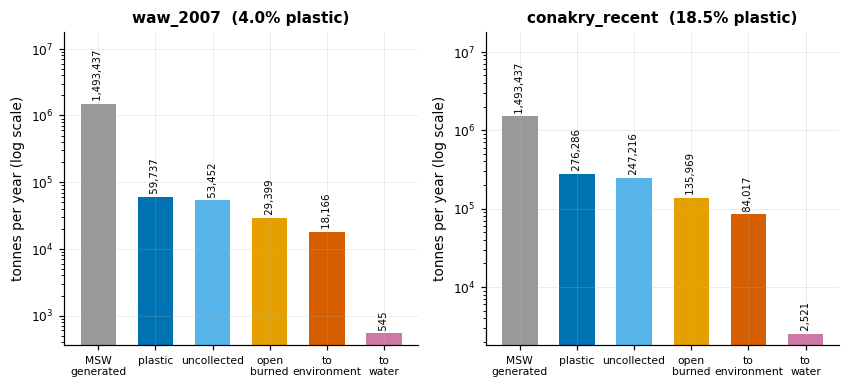

In [14]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from plasticwaste_tool import figstyle as FS
FS.use()

# ---- Figure 1: the chain, as a waterfall, under both scenarios ----------
fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.6), sharey=False)

for ax, sc in zip(axes, ["waw_2007", "conakry_recent"]):
    row = det[det.scenario == sc].iloc[0]
    steps = [("MSW\ngenerated", row.msw_t_yr, FS.OKABE_ITO["grey"]),
             ("plastic", row.plastic_t_yr, FS.OKABE_ITO["blue"]),
             ("uncollected", row.uncollected_t_yr, FS.OKABE_ITO["sky"]),
             ("open\nburned", row.burned_t_yr, FS.OKABE_ITO["orange"]),
             ("to\nenvironment", row.to_environment_t_yr, FS.OKABE_ITO["vermillion"]),
             ("to\nwater", row.to_water_t_yr, FS.OKABE_ITO["purple"])]
    ax.bar([s[0] for s in steps], [s[1] for s in steps],
           color=[s[2] for s in steps], width=0.62)
    ax.set_yscale("log")
    ax.set_title(f"{sc}  ({PAR.PLASTIC_SHARE_SCENARIOS[sc].value:.1%} plastic)")
    ax.set_ylabel("tonnes per year (log scale)")
    ax.tick_params(axis="x", labelsize=7)
    for i, s in enumerate(steps):
        ax.text(i, s[1], f" {s[1]:,.0f}", ha="center", va="bottom", fontsize=6.6,
                rotation=90)
    ax.set_ylim(top=row.msw_t_yr * 12)

fig.tight_layout()
FS.save(fig, "leak_01_chain_waterfall",
        "The waste chain under both plastic-share scenarios, log scale. The "
        "open-burning step is the one most national estimates omit: it "
        "removes roughly 55% of uncollected plastic as macro-debris, and "
        "skipping it would about double the leakage figure. Note the y axis "
        "is logarithmic -- each step is a large multiplicative reduction.")
plt.show()

saved  manual_qa\figures\leak_02_scenario_gap.png
caption: Monte Carlo distributions of annual plastic leakage under the two waste-composition scenarios (20,000 draws each). The intervals do not overlap. The binding constraint on this estimate is therefore not statistical -- no additional computation narrows it. It is that Guinea's only nationally representative composition figure dates from 2007, and the urban figures that contradict it cover Conakry alone.


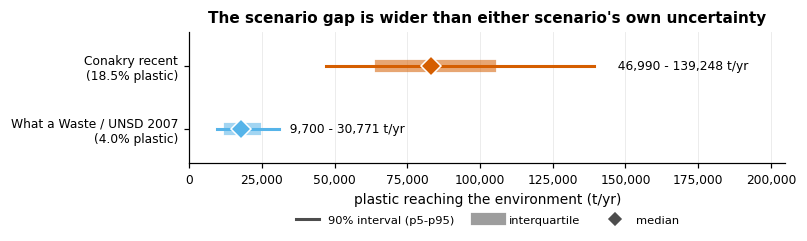

In [15]:
# ---- Figure 2: the scenario gap dwarfs the statistical interval ---------
fig, ax = plt.subplots(figsize=(7.4, 2.5))

for i, sc in enumerate(["waw_2007", "conakry_recent"]):
    s = np.asarray(mc[sc]["to_environment_t_yr"], float)
    q = np.quantile(s, [0.05, 0.25, 0.5, 0.75, 0.95])
    c = FS.SCENARIO_COLOURS[sc]
    ax.plot([q[0], q[4]], [i, i], color=c, linewidth=2.0, zorder=2)
    ax.plot([q[1], q[3]], [i, i], color=c, linewidth=8.0, alpha=0.55, zorder=3)
    ax.plot([q[2]], [i], marker="D", color=c, markersize=9,
            markeredgecolor="white", zorder=4)
    ax.text(q[4] * 1.04, i, f"  {q[0]:,.0f} - {q[4]:,.0f} t/yr",
            va="center", fontsize=8)

ax.set_yticks([0, 1])
ax.set_yticklabels(["What a Waste / UNSD 2007\n(4.0% plastic)",
                    "Conakry recent\n(18.5% plastic)"])
ax.set_xlabel("plastic reaching the environment (t/yr)")
ax.set_xlim(0, 205_000)
ax.set_ylim(-0.55, 1.55)
FS.thousands(ax, "x")
ax.set_title("The scenario gap is wider than either scenario's own uncertainty")
ax.grid(axis="y", visible=False)
ax.legend(handles=[
    Line2D([], [], color="0.3", linewidth=2.0, label="90% interval (p5-p95)"),
    Line2D([], [], color="0.3", linewidth=8.0, alpha=0.55, label="interquartile"),
    Line2D([], [], color="0.3", marker="D", linestyle="none", label="median")],
    loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=3, fontsize=7.5)

fig.tight_layout()
FS.save(fig, "leak_02_scenario_gap",
        "Monte Carlo distributions of annual plastic leakage under the two "
        "waste-composition scenarios (20,000 draws each). The intervals do "
        "not overlap. The binding constraint on this estimate is therefore "
        "not statistical -- no additional computation narrows it. It is that "
        "Guinea's only nationally representative composition figure dates "
        "from 2007, and the urban figures that contradict it cover Conakry "
        "alone.")
plt.show()

saved  manual_qa\figures\leak_03_variance_decomposition.png
caption: Global sensitivity of the leakage estimate (squared Spearman rank correlation, normalised). Open burning alone accounts for ~35% of the variance and has never been measured in Guinea. Collection coverage -- the single best-measured parameter, from a field survey -- accounts for about 0.1%, because at 9.7% national coverage its uncertainty cannot move the answer. The monitoring implication inverts the usual priority: a waste composition and disposal practice survey would buy far more precision than another collection census.


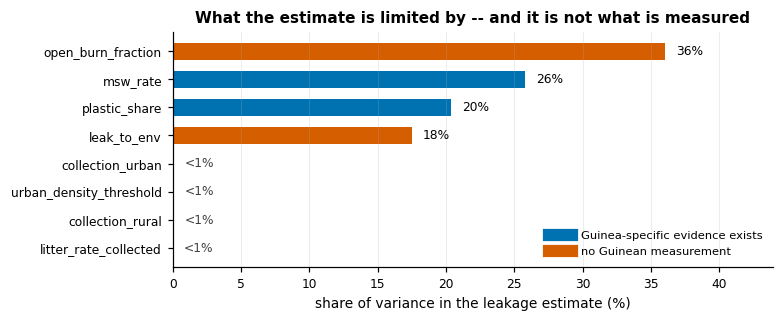

In [16]:
# ---- Figure 3: what the estimate is actually limited by -----------------
# Every parameter is kept, including the ones contributing almost nothing.
# Dropping them would hide the most important result in this figure: that
# collection coverage -- the only genuinely surveyed parameter -- is
# invisible on this axis.
var = UNC.contribution_to_variance(mc["waw_2007"]).sort_values("share_of_variance")
var = var[var["parameter"] != "p_to_water"]   # not in this chain step

guinea_specific = {"msw_rate", "plastic_share", "collection_urban",
                   "collection_rural"}
colours = [FS.OKABE_ITO["blue"] if p in guinea_specific else FS.OKABE_ITO["vermillion"]
           for p in var["parameter"]]

fig, ax = plt.subplots(figsize=(7.2, 3.0))
ax.barh(var["parameter"], var["share_of_variance"] * 100, color=colours,
        height=0.62)
for i, (p, sh) in enumerate(zip(var["parameter"], var["share_of_variance"])):
    label = f"{sh:.0%}" if sh >= 0.01 else "<1%"
    ax.text(sh * 100 + 0.8, i, label, va="center", fontsize=8,
            color="0.25" if sh < 0.01 else "black")
ax.set_xlabel("share of variance in the leakage estimate (%)")
ax.set_xlim(0, max(var["share_of_variance"]) * 100 * 1.22)
ax.set_title("What the estimate is limited by -- and it is not what is measured")
ax.grid(axis="y", visible=False)
ax.set_ylabel("")
ax.legend(handles=[
    Line2D([], [], color=FS.OKABE_ITO["blue"], linewidth=8,
           label="Guinea-specific evidence exists"),
    Line2D([], [], color=FS.OKABE_ITO["vermillion"], linewidth=8,
           label="no Guinean measurement")],
    loc="lower right", fontsize=7.5)

fig.tight_layout()
FS.save(fig, "leak_03_variance_decomposition",
        "Global sensitivity of the leakage estimate (squared Spearman rank "
        "correlation, normalised). Open burning alone accounts for ~35% of "
        "the variance and has never been measured in Guinea. Collection "
        "coverage -- the single best-measured parameter, from a field survey "
        "-- accounts for about 0.1%, because at 9.7% national coverage its "
        "uncertainty cannot move the answer. The monitoring implication "
        "inverts the usual priority: a waste composition and disposal "
        "practice survey would buy far more precision than another "
        "collection census.")
plt.show()

saved  manual_qa\figures\leak_04_by_region.png
caption: Plastic leakage by ADM1 region under the 2007 composition scenario. Error bars are 90% intervals from shared national parameter draws, so they are perfectly correlated across regions and must not be combined in quadrature. Absolute totals follow population; per capita rates run HIGHER in rural regions, because rural collection coverage is 2.1% against 23.7% urban.


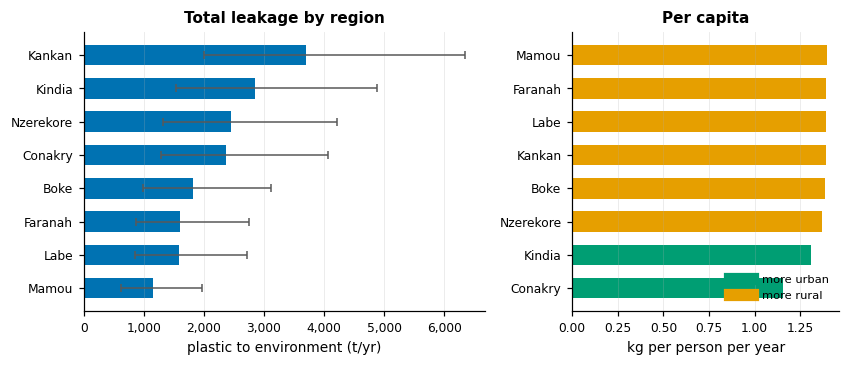

In [17]:
# ---- Figure 4: where the waste is generated -----------------------------
a = adm1.sort_values("to_env_t_yr_p50")
fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.4),
                         gridspec_kw={"width_ratios": [1.5, 1]})

ax = axes[0]
err = np.vstack([a["to_env_t_yr_p50"] - a["to_env_t_yr_p5"],
                 a["to_env_t_yr_p95"] - a["to_env_t_yr_p50"]])
ax.barh(a["adm1"], a["to_env_t_yr_p50"], xerr=err, height=0.62,
        color=FS.OKABE_ITO["blue"],
        error_kw=dict(ecolor="0.35", lw=1.0, capsize=2.5))
ax.set_xlabel("plastic to environment (t/yr)")
ax.set_title("Total leakage by region")
FS.thousands(ax, "x")
ax.grid(axis="y", visible=False)

ax = axes[1]
b = adm1.sort_values("leak_kg_per_capita_p50")
ax.barh(b["adm1"], b["leak_kg_per_capita_p50"], height=0.62,
        color=[FS.OKABE_ITO["orange"] if u < 0.35 else FS.OKABE_ITO["green"]
               for u in b["urban_share"]])
ax.set_xlabel("kg per person per year")
ax.set_title("Per capita")
ax.grid(axis="y", visible=False)
ax.legend(handles=[
    Line2D([], [], color=FS.OKABE_ITO["green"], linewidth=8, label="more urban"),
    Line2D([], [], color=FS.OKABE_ITO["orange"], linewidth=8, label="more rural")],
    loc="lower right", fontsize=7.5)

fig.tight_layout()
FS.save(fig, "leak_04_by_region",
        "Plastic leakage by ADM1 region under the 2007 composition scenario. "
        "Error bars are 90% intervals from shared national parameter draws, "
        "so they are perfectly correlated across regions and must not be "
        "combined in quadrature. Absolute totals follow population; per "
        "capita rates run HIGHER in rural regions, because rural collection "
        "coverage is 2.1% against 23.7% urban.")
plt.show()

saved  manual_qa\figures\leak_05_site_tonnage_vs_risk.png
caption: Per-site plastic tonnage against the ordinal mobilisation risk score. The two rank sites differently (Spearman rho=0.33; the top-15 lists share only 4 sites) because mobilisation risk is driven by terrain and hydrology while tonnage is driven by catchment population. Both belong in the layer: they answer 'how urgently would this site leak?' and 'how much material is at stake?' respectively. Tonnage is a catchment property, not an observation of the site -- no mass can be inverted from imagery at these sub-pixel extents.


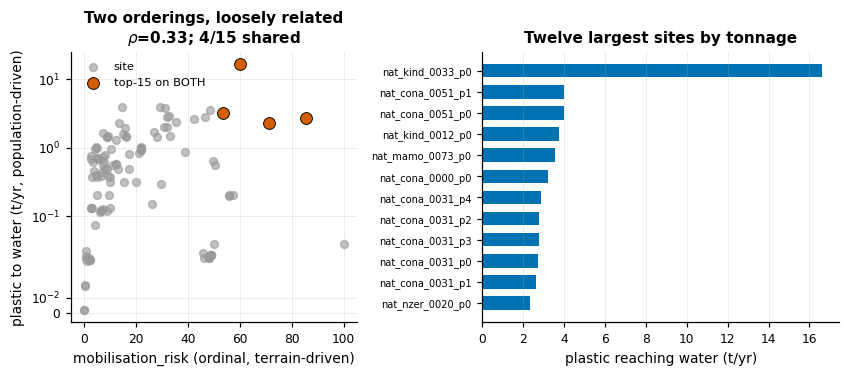

In [19]:
# ---- Figure 5: per-site tonnage vs ordinal mobilisation risk ------------
from scipy.stats import spearmanr

d = site_df.dropna(subset=["mobilisation_risk"]).copy()
rho = spearmanr(d["mobilisation_risk"], d["to_water_t_yr"]).statistic
top_mass = set(site_df.nlargest(15, "to_water_t_yr")["point_id"])
top_rank = set(d.nlargest(15, "mobilisation_risk")["point_id"])

fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.5),
                         gridspec_kw={"width_ratios": [1, 1.25]})

ax = axes[0]
both = d["point_id"].isin(top_mass & top_rank)
ax.scatter(d.loc[~both, "mobilisation_risk"], d.loc[~both, "to_water_t_yr"],
           s=26, alpha=0.6, color=FS.OKABE_ITO["grey"], label="site")
ax.scatter(d.loc[both, "mobilisation_risk"], d.loc[both, "to_water_t_yr"],
           s=60, color=FS.OKABE_ITO["vermillion"], edgecolor="black",
           linewidth=0.6, zorder=3, label="top-15 on BOTH")
ax.set_yscale("symlog", linthresh=0.05)
ax.set_xlabel("mobilisation_risk (ordinal, terrain-driven)")
ax.set_ylabel("plastic to water (t/yr, population-driven)")
ax.set_title(f"Two orderings, loosely related\n$\\rho$={rho:.2f}; "
             f"{len(top_mass & top_rank)}/15 shared")
ax.legend(loc="upper left", fontsize=7.5)

ax = axes[1]
top = site_df.nlargest(12, "to_water_t_yr").sort_values("to_water_t_yr")
ax.barh(top["point_id"], top["to_water_t_yr"], height=0.64,
        color=FS.OKABE_ITO["blue"])
ax.set_xlabel("plastic reaching water (t/yr)")
ax.set_title("Twelve largest sites by tonnage")
ax.tick_params(axis="y", labelsize=6.5)
ax.grid(axis="y", visible=False)

fig.tight_layout()
FS.save(fig, "leak_05_site_tonnage_vs_risk",
        "Per-site plastic tonnage against the ordinal mobilisation risk "
        "score. The two rank sites differently (Spearman rho=0.33; the "
        "top-15 lists share only 4 sites) because mobilisation risk is "
        "driven by terrain and hydrology while tonnage is driven by "
        "catchment population. Both belong in the layer: they answer 'how "
        "urgently would this site leak?' and 'how much material is at "
        "stake?' respectively. Tonnage is a catchment property, not an "
        "observation of the site -- no mass can be inverted from imagery at "
        "these sub-pixel extents.")
plt.show()

## 10. What to carry into the methodology

**The headline, with its range intact.** Plastic reaching the Guinean
environment is **18,000–84,000 t/yr** depending on which waste-composition
figure is believed, with a 90% interval of roughly ±60% *within* either
scenario. Quote the scenario range first and the statistical interval second;
quoting a single central value would misrepresent what is known.

**Three independent checks pass**, and all three exercise the front of the
chain only:

| Check | Result |
|---|---|
| Population vs UN WPP 2020 | +0.6% |
| Implied vs reported national collection | +8.5% |
| Modelled vs published national MSW tonnage | −4.8% |

No check exists for open burning, environmental leakage or transport to water,
because no Guinean measurement of them exists. Say so.

**The uncertainty is structural, not statistical.** The scenario gap (4.6×)
exceeds either scenario's own interval. More computation will not narrow it;
a national waste characterisation survey would.

**The monitoring recommendation inverts the usual one.** Collection coverage —
the best-measured parameter — contributes ~0.1% of variance, because at 9.7%
coverage its uncertainty cannot move the answer. Open burning contributes
~35–39% and has never been measured in Guinea. Fund a disposal-practice and
composition survey, not another collection census.

**Per-site tonnage and mobilisation risk are different orderings** and both
belong in the layer. They answer "how much is at stake?" and "how urgently
would it leak?" respectively, and the top-15 lists disagree substantially.

**Two conventions must be stated, not buried**: the DEGURBA urban threshold
(300–1,500/km², costing <3% of the national total) and the 5 km catchment
radius (a UNEP/IUCN convention, with the sensitivity table showing its cost).

**The limitation to state plainly**: this is a catchment property refined by
site attributes, not an observation of any site. Two adjacent sites with the
same catchment receive the same mass estimate however different they look —
because no remote-sensing product can currently distinguish them by mass at
14 m extent, and the module does not pretend otherwise.